# Ejecución del algoritmo MMAS para la búsqueda de rutas óptimas

In [1]:
from algoritmos.MMAS_adaptado import *

### Parámetros óptimos y matriz de distancias

In [3]:
N = 30
T = 200
alpha = 1.375
beta = 5
rho = 0.02
factor_tau_min = 10
Q = 1

cerrado = True
random_state = (123, 1234, 12345)
inicio = 13

file_path = "data/distancia_coche.csv"
dist_matrix_coches = LoadDistanceMatrix(file_path)

file_path = "data/distancia_bici.csv"
dist_matrix_bicis = LoadDistanceMatrix(file_path)

file_path = "data/distancia_pie.csv"
dist_matrix_pies = LoadDistanceMatrix(file_path)

### Descargar grafos y seleccción de nodos

In [5]:
import osmnx as ox
import networkx as nx
import pandas as pd
import folium

#Cargamos los grafos y los nodos guardados en nueva_mapa_vehiculos.ipynb
grafos = {modo: ox.load_graphml(f"data/grafos/grafo_{modo}.graphml") for modo in ("coche", "bici", "pie")}
seleccion = pd.read_csv("data/grafos/nodos_seleccionados_40.csv")

In [6]:
#Seleccionamos el centro de nuestro mapa para que Oms pueda ubicarlo correctamente
centro = [seleccion["lat"].mean(), seleccion["lon"].mean()]
def crear_mapa(G, color, centro):
    #Creamos el mapa interactivo
    m = folium.Map(location=centro, zoom_start=14, tiles="OpenStreetMap")
    #Intriducimos en el mapa su grafo correspondiente
    edges_modo = ox.graph_to_gdfs(G, nodes=False)[["geometry"]]
    folium.GeoJson(
        edges_modo,
        style_function=lambda f: {"color": color, "weight": 1.5}
    ).add_to(m)
    return m

# Añadimos los 40 nodos seleccionados anteriormente
def añadir_paradas(mapa):
    for _, fila in seleccion.iterrows():
            folium.CircleMarker([fila["lat"], fila["lon"]], radius=4, color="#444",
                            fill=True, fill_opacity=0.8,
                            tooltip=f"Parada {int(fila['id'])}").add_to(mapa)

# Añadimos la ruta que devuelve el algoritmo
def añadir_ruta(mapa, G, ruta, cerrado, color):
    lista_nodos_comun = seleccion["nodo"].tolist()
    #Orden de visita (si es cerrado se vuelve al nodo de inicio)
    orden = [int(i) for i in ruta]
    if cerrado:
        orden.append(orden[0])
    distancia = 0
    for k in range(len(orden) - 1):
        origen = lista_nodos_comun[orden[k]]
        destino = lista_nodos_comun[orden[k + 1]]
        #Camino mas corto por las calles entre dos paradas consecutivas
        camino = nx.shortest_path(G, origen, destino, weight="length")
        distancia += nx.path_weight(G, camino, weight="length")
        #Dibujamos ese tramo en el mapa
        tramo = ox.routing.route_to_gdf(G, camino, weight="length")[["geometry"]]
        folium.GeoJson(
            tramo,
            style_function=lambda f: {"color": color, "weight": 4},
            tooltip=f"Tramo {k + 1}: parada {orden[k] + 1} -> parada {orden[k + 1] + 1}"
        ).add_to(mapa)
    return distancia

### Ejecuciones para coche, bici y a pie

In [9]:
# Ejecución del algoritmo
best_outputs_coches, best_ouputs_global_coches, best_ant_f_coche, best_ant_x_coche = AntColonySystem(N, T, alpha, beta, rho, Q, dist_matrix_coches, cerrado, random_state, inicio, factor_tau_min)
best_outputs_bicis, best_ouputs_global_bicis, best_ant_f_bicis, best_ant_x_bicis = AntColonySystem(N, T, alpha, beta, rho, Q, dist_matrix_bicis, cerrado, random_state, inicio, factor_tau_min)
best_outputs_pie, best_ouputs_global_pie, best_ant_f_pie, best_ant_x_pie = AntColonySystem(N, T, alpha, beta, rho, Q, dist_matrix_pies, cerrado, random_state, inicio, factor_tau_min)

Iteration: 200 Best global (m): 19984.7 Best iter (m): 19984.7: 100%|██████████| 201/201 [00:10<00:00, 19.92it/s]
Iteration: 200 Best global (m): 19512.8 Best iter (m): 19512.8: 100%|██████████| 201/201 [00:10<00:00, 19.19it/s]
Iteration: 200 Best global (m): 14570.4 Best iter (m): 14570.4: 100%|██████████| 201/201 [00:10<00:00, 19.57it/s]


### Visualización de las evoluciones

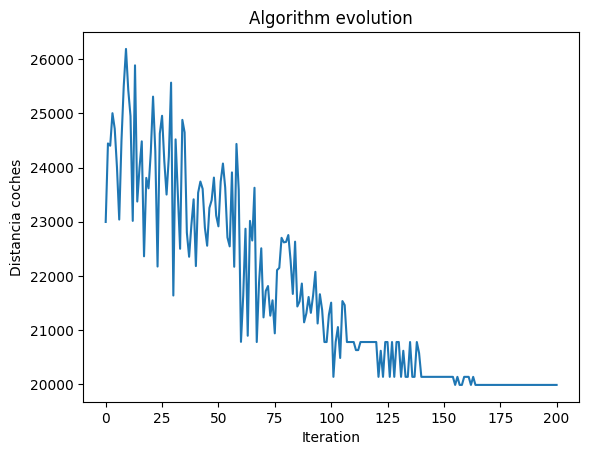

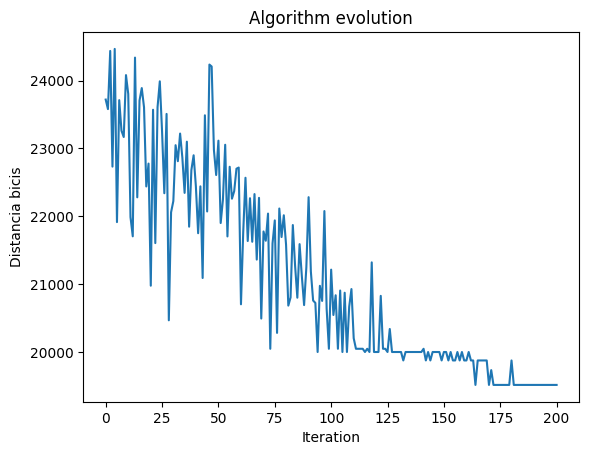

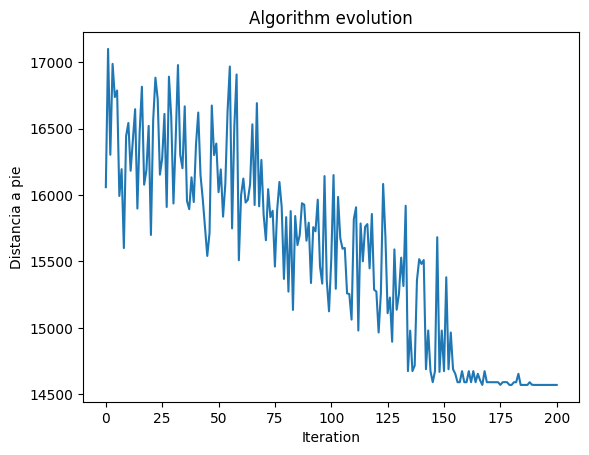

In [ ]:
# Visualización de la ejecución
VisualizaEvolucion(best_outputs_coches, "Distancia coches")
VisualizaEvolucion(best_outputs_bicis, "Distancia bicis")
VisualizaEvolucion(best_outputs_pie, "Distancia a pie")

### Caminos

In [11]:
m_mmas = crear_mapa(grafos["coche"], "#888888", centro) #Grafo en gris
distancia = añadir_ruta(m_mmas, grafos["coche"], best_ant_x_coche, cerrado, "red") #Ruta en rojo
añadir_paradas(m_mmas)
print(f"Distancia sobre el mapa: {distancia:.1f} m | EAS: {best_ant_f_coche:.1f} m")
m_mmas

Distancia sobre el mapa: 19984.7 m | EAS: 19984.7 m


In [12]:
m_mmas = crear_mapa(grafos["bici"], "#888888", centro) #Grafo en gris
distancia = añadir_ruta(m_mmas, grafos["bici"], best_ant_x_bicis, cerrado, "blue") #Ruta en rojo
añadir_paradas(m_mmas)
print(f"Distancia sobre el mapa: {distancia:.1f} m | EAS: {best_ant_f_bicis:.1f} m")
m_mmas

Distancia sobre el mapa: 19512.8 m | EAS: 19512.8 m


In [15]:
m_mmas = crear_mapa(grafos["pie"], "#888888", centro) #Grafo en gris
distancia = añadir_ruta(m_mmas, grafos["pie"], best_ant_x_pie, cerrado, "green") #Ruta en rojo
añadir_paradas(m_mmas)
print(f"Distancia sobre el mapa: {distancia:.1f} m | EAS: {best_ant_f_pie:.1f} m")
m_mmas

Distancia sobre el mapa: 14570.4 m | EAS: 14570.4 m
